# Lab 1 – Partie 1 : Régression (NYSE)
**Objectif** : prédire le prix de clôture du **jour suivant** d'une action à partir des données du jour (open, high, low, close, volume) avec un MLP PyTorch.

Plan : EDA → préparation → MLP → GridSearch → courbes → régularisation.

In [5]:
%pip install -q kagglehub

Note: you may need to restart the kernel to use updated packages.


In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, torch, torch.nn as nn
from collections import defaultdict
from torch.utils.data import TensorDataset, DataLoader
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin
import warnings; warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", DEVICE)

def build_mlp(d_in, d_out, hidden, dropout=0.0, batchnorm=False):
    layers, prev = [], d_in
    for h in hidden:
        layers.append(nn.Linear(prev, h))
        if batchnorm: layers.append(nn.BatchNorm1d(h))
        layers.append(nn.ReLU())
        if dropout > 0: layers.append(nn.Dropout(dropout))
        prev = h
    layers.append(nn.Linear(prev, d_out))
    return nn.Sequential(*layers)

OPTIMIZERS = {
    "adam":    lambda p, lr, wd: torch.optim.Adam(p, lr=lr, weight_decay=wd),
    "adamw":   lambda p, lr, wd: torch.optim.AdamW(p, lr=lr, weight_decay=wd),
    "sgd":     lambda p, lr, wd: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=wd),
    "rmsprop": lambda p, lr, wd: torch.optim.RMSprop(p, lr=lr, weight_decay=wd),
}

class _TorchBase(BaseEstimator):
    """Wrapper PyTorch compatible scikit-learn (fit / predict / score) -> utilisable dans GridSearchCV."""
    def __init__(self, hidden=(64, 32), lr=1e-3, optimizer="adam", epochs=20, batch_size=256,
                 dropout=0.0, weight_decay=0.0, batchnorm=False, patience=0, use_class_weight=False):
        self.hidden = hidden; self.lr = lr; self.optimizer = optimizer; self.epochs = epochs
        self.batch_size = batch_size; self.dropout = dropout; self.weight_decay = weight_decay
        self.batchnorm = batchnorm; self.patience = patience; self.use_class_weight = use_class_weight

    def _forward(self, X):
        self.model_.eval(); outs = []
        with torch.no_grad():
            for i in range(0, len(X), 8192):
                outs.append(self.model_(torch.as_tensor(X[i:i + 8192], dtype=torch.float32, device=DEVICE)))
        return torch.cat(outs)

    def _eval(self, X, yt):
        out = self._forward(X)
        return self._loss(out, yt).item(), self._metric(out, yt).item()

    def fit(self, X, y, X_val=None, y_val=None):
        X = np.asarray(X, dtype=np.float32)
        yt = self._setup(y)
        torch.manual_seed(SEED)
        self.model_ = build_mlp(X.shape[1], self.n_out_, self.hidden, self.dropout, self.batchnorm).to(DEVICE)
        opt = OPTIMIZERS[self.optimizer](self.model_.parameters(), self.lr, self.weight_decay)
        loader = DataLoader(TensorDataset(torch.as_tensor(X, device=DEVICE), yt),
                            batch_size=self.batch_size, shuffle=True, drop_last=self.batchnorm)
        self.history_ = defaultdict(list); best, wait, best_state = np.inf, 0, None
        if X_val is not None:
            X_val = np.asarray(X_val, dtype=np.float32); yv = self._encode(y_val)
        for ep in range(self.epochs):
            self.model_.train()
            for xb, yb in loader:
                opt.zero_grad(); self._loss(self.model_(xb), yb).backward(); opt.step()
            trl, trm = self._eval(X, yt)
            self.history_["train_loss"].append(trl); self.history_["train_metric"].append(trm)
            if X_val is not None:
                vl, vm = self._eval(X_val, yv)
                self.history_["val_loss"].append(vl); self.history_["val_metric"].append(vm)
                if self.patience > 0:  # early stopping
                    if vl < best - 1e-6:
                        best, wait = vl, 0
                        best_state = {k: v.clone() for k, v in self.model_.state_dict().items()}
                    else:
                        wait += 1
                        if wait >= self.patience: break
        if best_state is not None: self.model_.load_state_dict(best_state)
        return self

class TorchRegressor(RegressorMixin, _TorchBase):
    def _encode(self, y): return torch.as_tensor(np.asarray(y, dtype=np.float32).reshape(-1, 1), device=DEVICE)
    def _setup(self, y): self.n_out_ = 1; return self._encode(y)
    def _loss(self, out, yb): return nn.functional.mse_loss(out, yb)
    def _metric(self, out, yb): return 1 - ((yb - out) ** 2).sum() / ((yb - yb.mean()) ** 2).sum()   # R2
    def predict(self, X): return self._forward(np.asarray(X, dtype=np.float32)).cpu().numpy().ravel()

class TorchClassifier(ClassifierMixin, _TorchBase):
    def _encode(self, y): return torch.as_tensor(np.searchsorted(self.classes_, np.asarray(y)), dtype=torch.long, device=DEVICE)
    def _setup(self, y):
        self.classes_ = np.unique(y); self.n_out_ = len(self.classes_)
        yt = self._encode(y)
        if self.use_class_weight:
            cnt = torch.bincount(yt, minlength=self.n_out_).float()
            self.weights_ = (len(yt) / (self.n_out_ * cnt.clamp(min=1))).to(DEVICE)
        else:
            self.weights_ = None
        return yt
    def _loss(self, out, yb): return nn.functional.cross_entropy(out, yb, weight=self.weights_)
    def _metric(self, out, yb): return (out.argmax(1) == yb).float().mean()   # accuracy
    def predict(self, X): return self.classes_[self._forward(np.asarray(X, dtype=np.float32)).argmax(1).cpu().numpy()]

def plot_history(h, metric_name, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(h["train_loss"], label="Train"); ax[0].plot(h["val_loss"], label="Test")
    ax[0].set(title=f"{title} Loss / Epochs", xlabel="Epoch", ylabel="Loss"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(h["train_metric"], label="Train"); ax[1].plot(h["val_metric"], label="Test")
    ax[1].set(title=f"{title} {metric_name} / Epochs", xlabel="Epoch", ylabel=metric_name); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

Device : cpu


## 0. Chargement des données

In [7]:
import kagglehub
path = kagglehub.dataset_download("dgawlik/nyse")
print(path)
prices = pd.read_csv(f"{path}/prices-split-adjusted.csv", parse_dates=["date"])
securities = pd.read_csv(f"{path}/securities.csv")
prices.head()

/kaggle/input/datasets/dgawlik/nyse


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


## 1. Analyse exploratoire (EDA)

In [8]:
print(prices.shape); prices.info()
display(prices.describe().T)
print("Valeurs manquantes :\n", prices.isna().sum())
print("Doublons :", prices.duplicated().sum(), "| Nb d'actions :", prices.symbol.nunique())
print("Période :", prices.date.min(), "->", prices.date.max())

(851264, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 45.5+ MB


,count,mean,min,25%,50%,75%,max,std
date,851264,2013-07-21 02:56:29.294037760,2010-01-04 00:00:00,2011-10-19 00:00:00,2013-08-02 00:00:00,2015-04-24 00:00:00,2016-12-30 00:00:00,NaN
open,851264.0,64.993618,1.66,31.27,48.459999,75.120003,1584.439941,75.203893
close,851264.0,65.011913,1.59,31.292776,48.48,75.139999,1578.130005,75.201216
low,851264.0,64.336541,1.5,30.940001,47.970001,74.400002,1549.939941,74.459518
high,851264.0,65.639748,1.81,31.620001,48.959999,75.849998,1600.930054,75.906861
volume,851264.0,5415112.640027,0.0,1221500.0,2476250.0,5222500.0,859643400.0,12494681.433084


Valeurs manquantes :
 date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64
Doublons : 0 | Nb d'actions : 501
Période : 2010-01-04 00:00:00 -> 2016-12-30 00:00:00


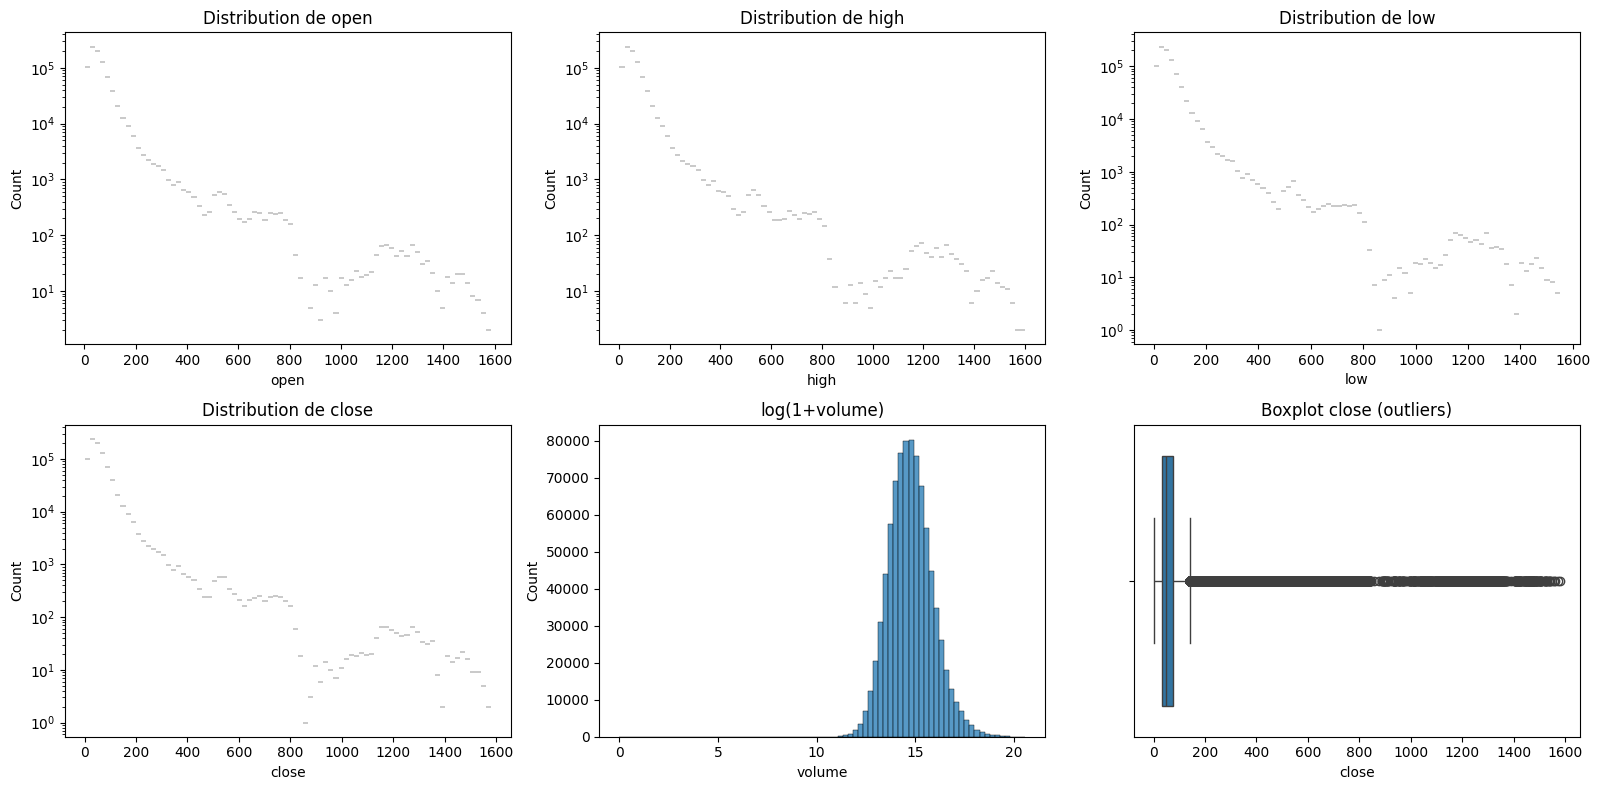

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, c in zip(ax.ravel()[:4], ["open", "high", "low", "close"]):
    sns.histplot(prices[c], bins=80, ax=a, log_scale=(False, True)); a.set_title(f"Distribution de {c}")
sns.histplot(np.log1p(prices["volume"]), bins=80, ax=ax[1, 1]); ax[1, 1].set_title("log(1+volume)")
sns.boxplot(x=prices["close"], ax=ax[1, 2]); ax[1, 2].set_title("Boxplot close (outliers)")
plt.tight_layout(); plt.show()

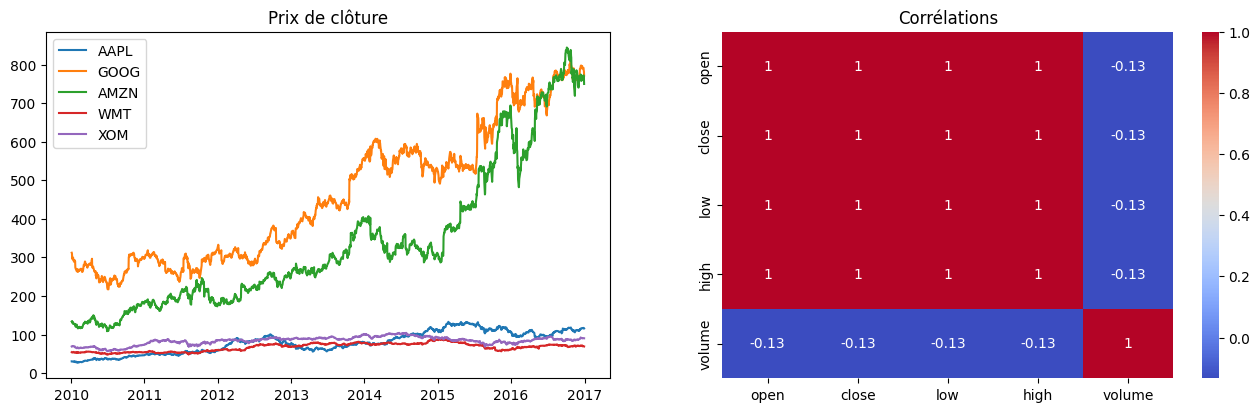

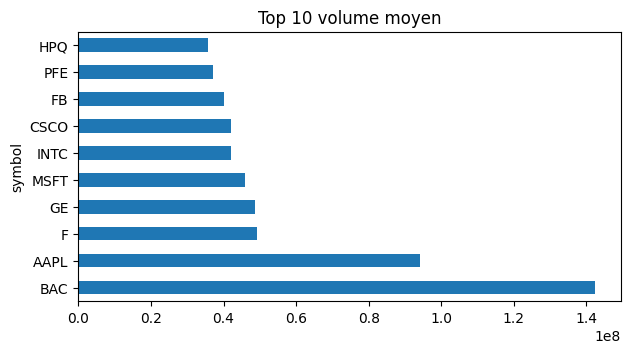

In [10]:
# Évolution temporelle de quelques actions + corrélations
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for s in ["AAPL", "GOOG", "AMZN", "WMT", "XOM"]:
    d = prices[prices.symbol == s]
    if len(d): ax[0].plot(d.date, d.close, label=s)
ax[0].set_title("Prix de clôture"); ax[0].legend()
sns.heatmap(prices[["open", "close", "low", "high", "volume"]].corr(), annot=True, cmap="coolwarm", ax=ax[1]); ax[1].set_title("Corrélations")
plt.show()
top = prices.groupby("symbol")["volume"].mean().nlargest(10)
top.plot(kind="barh", title="Top 10 volume moyen", figsize=(7, 3.5)); plt.show()

**Observations EDA**
- 851 264 lignes, 501 actions, du 04/01/2010 au 30/12/2016 ; **aucune valeur manquante, aucun doublon**.
- Les prix sont très asymétriques : moyenne ≈ 65 $, médiane ≈ 48 $, maximum ≈ 1 578 $ (quelques titres très chers, ex. GOOG/AMZN) → beaucoup d'outliers « naturels », conservés.
- Le volume est extrêmement asymétrique (moyenne 5,4 M, max 860 M) → transformation `log1p`.
- `open`, `high`, `low`, `close` sont quasi parfaitement corrélés (multicolinéarité) : le prix du jour est très informatif sur celui du lendemain.

## 2. Préparation des données
Cible = `close` du jour suivant (par action). Split **temporel** : train < 2016, test = 2016 (pas de fuite du futur).

In [11]:
from sklearn.preprocessing import StandardScaler
FEATURES = ["open", "high", "low", "close", "volume"]
df = prices.sort_values(["symbol", "date"]).copy()
df["target"] = df.groupby("symbol")["close"].shift(-1)
df = df.dropna(subset=["target"])
df["volume"] = np.log1p(df["volume"])

train, test = df[df.date < "2016-01-01"], df[df.date >= "2016-01-01"]
sx, sy = StandardScaler(), StandardScaler()
X_train = sx.fit_transform(train[FEATURES]); X_test = sx.transform(test[FEATURES])
y_train = sy.fit_transform(train[["target"]]).ravel(); y_test = sy.transform(test[["target"]]).ravel()
print(X_train.shape, X_test.shape)

(725139, 5) (125624, 5)


## 3. Modèle MLP de base (PyTorch)

In [12]:
base = TorchRegressor(hidden=(64, 32), lr=1e-3, optimizer="adam", epochs=20, batch_size=512)
base.fit(X_train, y_train, X_test, y_test)
print("R2 train :", base.score(X_train, y_train), "| R2 test :", base.score(X_test, y_test))

R2 train : 0.9994778018018183 | R2 test : 0.9995570261485016


## 4. GridSearchCV (sklearn)
Sous-échantillon de 30 000 lignes pour aller vite.

In [13]:
from sklearn.model_selection import GridSearchCV, KFold
idx = np.random.choice(len(X_train), 30000, replace=False)
param_grid = {
    "lr": [1e-3, 1e-2],
    "optimizer": ["adam", "rmsprop", "sgd"],
    "hidden": [(32,), (64, 32), (128, 64, 32)],
    "epochs": [10, 20],
    "batch_size": [256],
}
grid = GridSearchCV(TorchRegressor(), param_grid, cv=KFold(3, shuffle=True, random_state=SEED), scoring="r2", n_jobs=1, verbose=1)
grid.fit(X_train[idx], y_train[idx])
print("Meilleurs hyperparamètres :", grid.best_params_, "| R2 CV :", grid.best_score_)
pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(10)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Meilleurs hyperparamètres : {'batch_size': 256, 'epochs': 10, 'hidden': (32,), 'lr': 0.001, 'optimizer': 'rmsprop'} | R2 CV : 0.9994313513787466


,params,mean_test_score,std_test_score
1,"{'batch_size': 256, 'epochs': 10, 'hidden': (3...",0.999431,0.000070
24,"{'batch_size': 256, 'epochs': 20, 'hidden': (6...",0.999377,0.000004
31,"{'batch_size': 256, 'epochs': 20, 'hidden': (1...",0.999358,0.000083
18,"{'batch_size': 256, 'epochs': 20, 'hidden': (3...",0.999354,0.000167
30,"{'batch_size': 256, 'epochs': 20, 'hidden': (1...",0.999327,0.000106
35,"{'batch_size': 256, 'epochs': 20, 'hidden': (1...",0.999318,0.000090
0,"{'batch_size': 256, 'epochs': 10, 'hidden': (3...",0.999306,0.000083
29,"{'batch_size': 256, 'epochs': 20, 'hidden': (6...",0.999305,0.000021
12,"{'batch_size': 256, 'epochs': 10, 'hidden': (1...",0.999299,0.000146
9,"{'batch_size': 256, 'epochs': 10, 'hidden': (6...",0.999231,0.000164


## 5. Entraînement final + courbes Loss/Epochs et Accuracy(R²)/Epochs

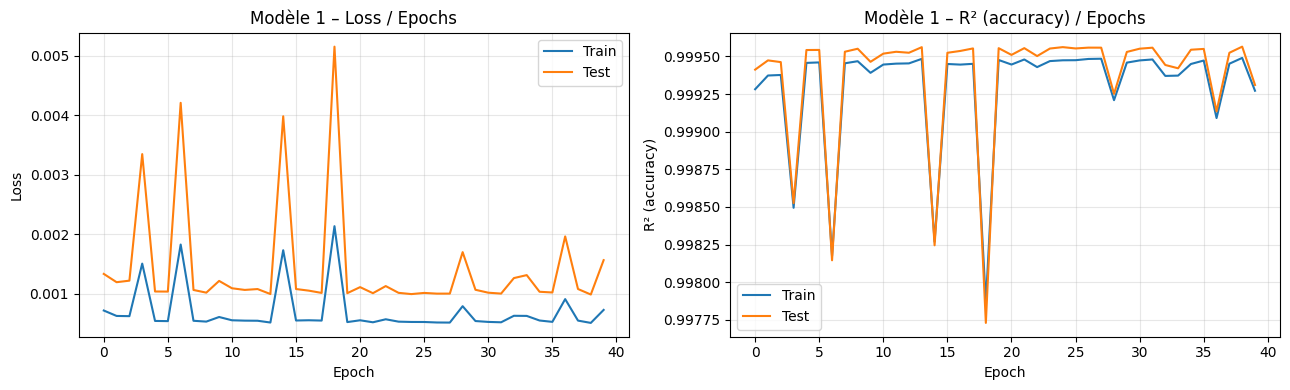

,modèle,R2_train,RMSE$_train,MAE$_train,R2_test,RMSE$_test,MAE$_test
0,Baseline,0.999272,1.851059,0.813259,0.99931,2.713128,1.176862


In [14]:
best = TorchRegressor(**{**grid.best_params_, "epochs": 40, "batch_size": 512})
best.fit(X_train, y_train, X_test, y_test)
plot_history(best.history_, "R² (accuracy)", "Modèle 1 –")

def reg_report(m, name):
    out = {}
    for n, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        p = sy.inverse_transform(m.predict(X).reshape(-1, 1)).ravel(); t = sy.inverse_transform(y.reshape(-1, 1)).ravel()
        out[f"R2_{n}"] = m.score(X, y); out[f"RMSE$_{n}"] = np.sqrt(np.mean((p - t) ** 2)); out[f"MAE$_{n}"] = np.mean(np.abs(p - t))
    return {"modèle": name, **out}
pd.DataFrame([reg_report(best, "Baseline")])

### Interprétation – Modèle 1 (RMSprop, lr=1e-3, 1 couche de 32 neurones, 40 epochs)
- **Performance** : R² train = 0,9993 et R² test = 0,9993 ; RMSE test ≈ 2,71 $ et MAE test ≈ 1,18 $ (pour un prix moyen de 65 $). Le modèle explique quasiment toute la variance.
- **Pas de sur-apprentissage** : les courbes train et test sont très proches (loss de l'ordre de 10⁻³) et la loss test ne remonte pas durablement. Le R² test est même parfois légèrement supérieur au R² train, car la période de test (2016) est un peu moins difficile et parce que la loss train est calculée pendant l'entraînement, après des mises à jour bruitées.
- **Instabilité** : on observe des pics ponctuels (epochs ≈ 3, 6, 14, 18, 28, 36) où la loss monte brutalement avant de revenir. Cela vient de l'optimiseur RMSprop avec un learning rate constant et de batchs contenant des actions à prix très élevés ; le modèle converge mais n'est pas stable epoch par epoch.
- **Nuance importante** : prédire `close(t+1)` à partir de `close(t)` est une tâche presque triviale (le prix de demain ≈ celui d'aujourd'hui). Un R² de 0,999 ne signifie donc pas que le modèle « prédit le marché » ; une baseline naïve `close(t+1)=close(t)` obtiendrait déjà un score très proche.

## 6. Techniques de régularisation
Dropout, L2 (weight decay), BatchNorm, Early stopping, et combinaison.

,R2_train,RMSE$_train,MAE$_train,R2_test,RMSE$_test,MAE$_test
modèle,,,,,,
Baseline,0.9993,1.8511,0.8133,0.9993,2.7131,1.1769
Dropout 0.2,0.9932,5.6698,1.9441,0.9923,9.0937,3.3349
L2 (wd=1e-3),0.9990,2.1491,0.9629,0.9991,3.1582,1.3794
BatchNorm,0.9989,2.3109,1.2841,0.9992,2.9854,1.5993
Early stopping,0.9995,1.5585,0.7165,0.9996,2.1636,0.9636
Combiné,0.9987,2.4644,1.5797,0.9990,3.2148,1.8552


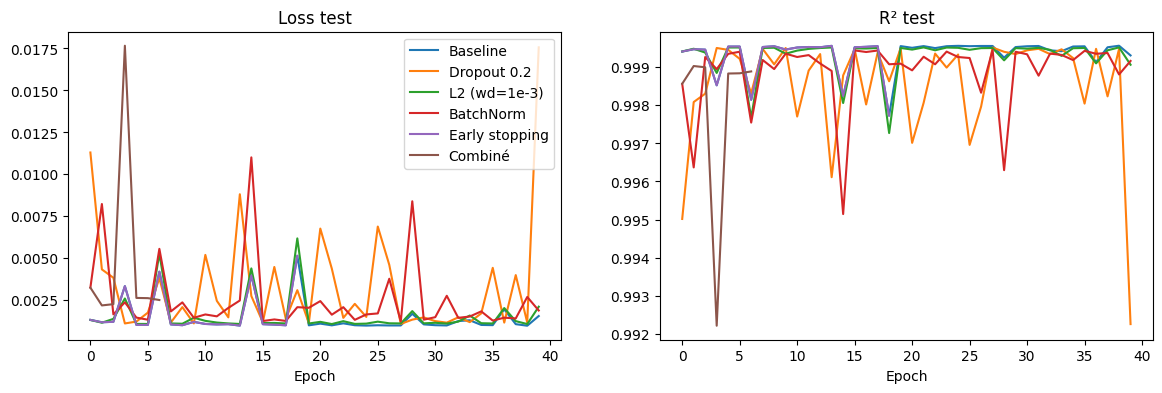

In [15]:
bp = {**grid.best_params_, "epochs": 40, "batch_size": 512}
configs = {
    "Baseline": {},
    "Dropout 0.2": {"dropout": 0.2},
    "L2 (wd=1e-3)": {"weight_decay": 1e-3},
    "BatchNorm": {"batchnorm": True},
    "Early stopping": {"patience": 5},
    "Combiné": {"dropout": 0.1, "weight_decay": 1e-4, "batchnorm": True, "patience": 5},
}
rows, hist = [], {}
for name, extra in configs.items():
    m = TorchRegressor(**{**bp, **extra}).fit(X_train, y_train, X_test, y_test)
    rows.append(reg_report(m, name)); hist[name] = m.history_
res = pd.DataFrame(rows).set_index("modèle"); display(res.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for n, h in hist.items():
    ax[0].plot(h["val_loss"], label=n); ax[1].plot(h["val_metric"], label=n)
ax[0].set(title="Loss test", xlabel="Epoch"); ax[1].set(title="R² test", xlabel="Epoch"); ax[0].legend(); plt.show()

### Comparaison des techniques de régularisation (partie 1)

| Modèle | R² test | RMSE test ($) | MAE test ($) |
|---|---|---|---|
| Baseline | 0,9993 | 2,71 | 1,18 |
| Dropout 0,2 | 0,9923 | 9,09 | 3,33 |
| L2 (wd=1e-3) | 0,9991 | 3,16 | 1,38 |
| BatchNorm | 0,9992 | 2,99 | 1,60 |
| **Early stopping** | **0,9996** | **2,16** | **0,96** |
| Combiné | 0,9990 | 3,21 | 1,86 |

- Le modèle de base **ne sur-apprend pas** (train ≈ test) : la régularisation n'a donc presque rien à corriger, et la plupart des techniques *dégradent* légèrement le résultat (légère perte de capacité).
- **Dropout** est le plus pénalisant (RMSE 9,09 $, courbes très instables) : sur un petit réseau de régression, éteindre des neurones détruit l'information nécessaire pour reproduire des valeurs précises → sous-apprentissage.
- **L2** et **BatchNorm** donnent des résultats proches de la baseline, un peu moins bons ; BatchNorm reste plus bruité.
- **Early stopping** est la seule technique qui améliore le modèle (RMSE 2,16 $ vs 2,71 $) : comme la loss oscille fortement, elle conserve les poids de la meilleure epoch au lieu de ceux de la dernière epoch qui peut tomber sur un pic.
- La combinaison de plusieurs techniques n'est pas meilleure que chacune séparément : trop de régularisation pour un modèle qui n'en avait pas besoin.

## Synthèse personnelle
Ce TP m'a permis de construire un pipeline complet de régression avec PyTorch : EDA, préparation (split temporel pour éviter la fuite du futur, standardisation ajustée sur le train), MLP, puis recherche d'hyperparamètres avec `GridSearchCV` grâce à un wrapper compatible scikit-learn. J'ai appris que (1) un R² très élevé peut cacher une tâche facile et qu'il faut toujours le comparer à une baseline naïve, (2) la régularisation n'est utile que s'il y a du sur-apprentissage, sinon elle peut dégrader le modèle, et (3) l'early stopping est une technique simple et efficace, surtout quand l'entraînement est instable.